In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from shared import (CODED_CSV, COMPARISON_CSV, THEMES, NATIVE, LUME, INK, GRID,
                    labels_for, save)

In [ ]:
df = pd.read_csv(CODED_CSV, parse_dates=["date"])
nat = df[df["brand"] == "Native"].copy()
lume = df[df["brand"] == "Lume"].copy()
len(nat), len(lume)

(627, 456)

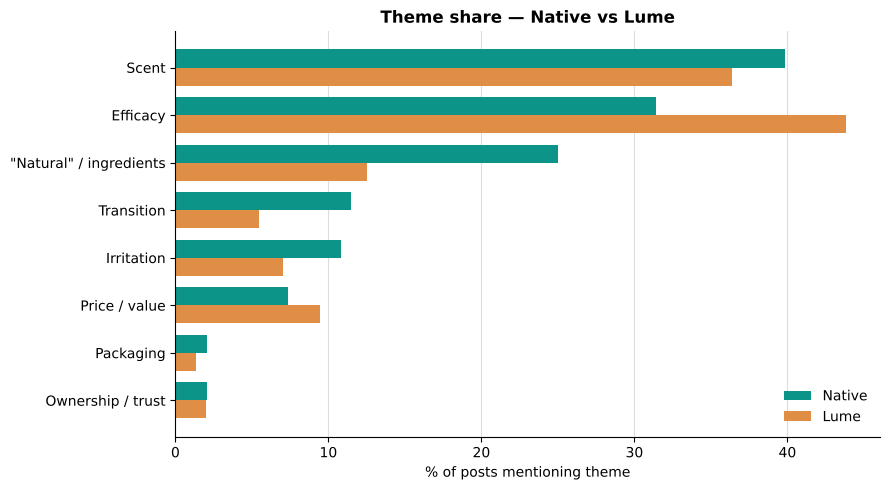

In [ ]:
order = sorted(THEMES, key=lambda t: nat[t].mean())
nat_share = [nat[t].mean() * 100 for t in order]
lume_share = [lume[t].mean() * 100 for t in order]

y = np.arange(len(order))
h = 0.38

fig, ax = plt.subplots(figsize=(9, 5))
ax.barh(y + h / 2, nat_share, height=h, color=NATIVE, label="Native")
ax.barh(y - h / 2, lume_share, height=h, color=LUME, label="Lume")
ax.set_yticks(y)
ax.set_yticklabels(labels_for(order))
ax.set_xlabel("% of posts mentioning theme")
ax.set_title("Theme share — Native vs Lume", fontweight="bold")
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
save(fig, "theme_share_vs_lume.png")

In [ ]:
min_n = 25
rows = []
for theme in THEMES:
    nn, ln = int(nat[theme].sum()), int(lume[theme].sum())
    if nn >= min_n and ln >= min_n:
        rows.append({
            "theme": theme,
            "native_sent": nat.loc[nat[theme] == 1, "vader"].mean(),
            "lume_sent": lume.loc[lume[theme] == 1, "vader"].mean(),
            "native_n": nn,
            "lume_n": ln,
        })

comparison = pd.DataFrame(rows).sort_values("native_sent")
comparison

,theme,native_sent,lume_sent,native_n,lume_n
0,irritation,0.102850,-0.072797,68,32
4,price_value,0.168809,-0.126140,46,43
1,efficacy,0.237746,0.241992,197,200
3,transition,0.313422,0.261756,72,25
2,scent,0.343086,0.263540,250,166
5,ingredients,0.355016,0.419028,157,57


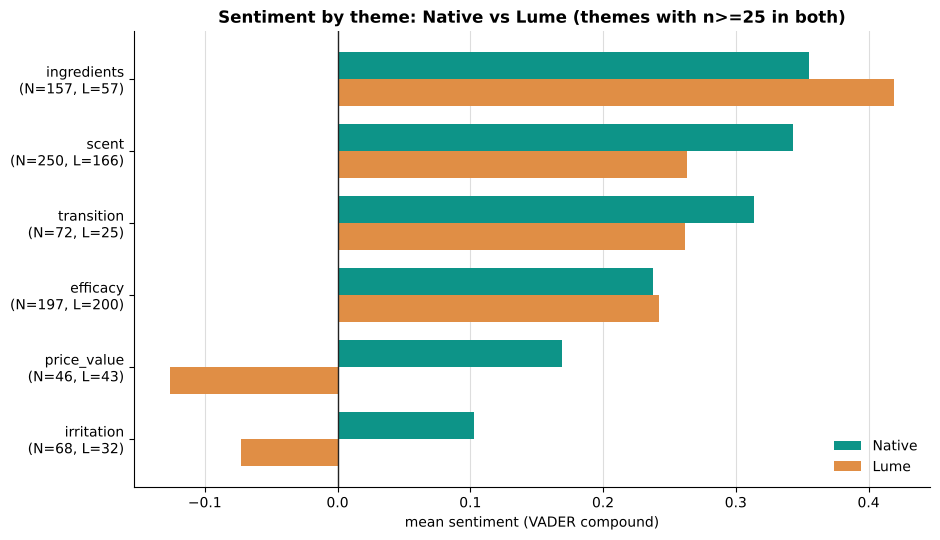

In [ ]:
ylabels = [f"{t}\n(N={n}, L={l})"
           for t, n, l in zip(comparison["theme"], comparison["native_n"], comparison["lume_n"])]
y = np.arange(len(comparison))
h = 0.38

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.barh(y + h / 2, comparison["native_sent"], height=h, color=NATIVE, label="Native")
ax.barh(y - h / 2, comparison["lume_sent"], height=h, color=LUME, label="Lume")
ax.axvline(0, color=INK, lw=1)
ax.set_yticks(y)
ax.set_yticklabels(ylabels)
ax.set_xlabel("mean sentiment (VADER compound)")
ax.set_title("Sentiment by theme: Native vs Lume (themes with n>=25 in both)", fontweight="bold")
ax.xaxis.grid(True, color=GRID, lw=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, loc="lower right")
save(fig, "sentiment_by_theme_vs_lume.png")

In [ ]:
comparison.to_csv(COMPARISON_CSV, index=False)